In [26]:
import tensorflow as tf
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Input
from keras.models import Sequential
import matplotlib.pyplot as plt
from keras.datasets import fashion_mnist
from keras.optimizers import SGD
import numpy as np
import matplotlib.pyplot as plt

In [3]:
(train_X, train_y), (test_X, test_y) = fashion_mnist.load_data()
print('X_train: ' + str(train_X.shape))
print('Y_train: ' + str(train_y.shape))
print('X_test:  '  + str(test_X.shape))
print('Y_test:  '  + str(test_y.shape))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
X_train: (60000, 28, 28)
Y_train: (60000,)
X_test:  (10000, 28, 28)
Y_test:  (10000,)


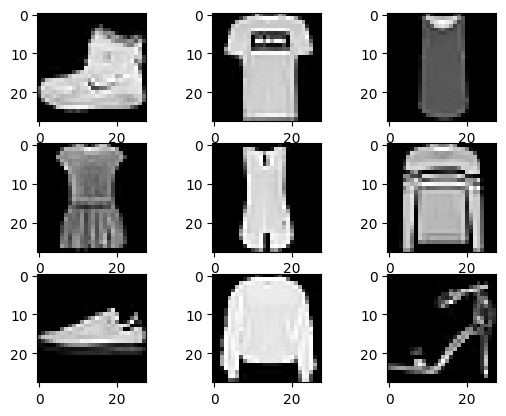

In [4]:
train_X = train_X / 255
test_X = test_X / 255
for i in range(9):
  plt.subplot(330 + 1 + i) #rows col pos
  plt.imshow(train_X[i], cmap=plt.get_cmap('gray'))
plt.show()

In [5]:
model_1 = Sequential(
    [ Input((28,28, 1)),
      Conv2D(64, (5, 5), activation='relu', name='layer1'),
      MaxPooling2D(pool_size=(2, 2), name='layer2'),
      Conv2D(128, (5, 5), activation="relu", name='layer3'),
      MaxPooling2D(pool_size=(2, 2), name='layer4'),
      Flatten(),
      Dense(128, activation="relu", name="layer5"),
      Dense(10, activation="softmax")
    ]
)

In [6]:
model_1.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [7]:
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Conv2D)                 │ (None, 24, 24, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (MaxPooling2D)           │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer3 (Conv2D)                 │ (None, 8, 8, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer4 (MaxPooling2D)           │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer5 (Dense)                  │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 470,154 (1.79 MB)

 Trainable params: 470,154 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history_1 = model_1.fit(x=train_X, y=train_y, epochs=15, validation_split=0.2)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9706 - loss: 0.0774 - val_accuracy: 0.9161 - val_loss: 0.3322
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9737 - loss: 0.0698 - val_accuracy: 0.9173 - val_loss: 0.3718
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9760 - loss: 0.0647 - val_accuracy: 0.9125 - val_loss: 0.3733
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9794 - loss: 0.0564 - val_accuracy: 0.9094 - val_loss: 0.4240
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9803 - loss: 0.0536 - val_accuracy: 0.9135 - val_loss: 0.4370
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9824 - loss: 0.0471 - val_accuracy: 0.9124 - val_loss: 0.4133
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9828 - loss: 0.0473 - val_accuracy: 0.9086 - val_loss: 0.4842
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9838 - loss: 0.0415 -

In [10]:
model_1.evaluate(x=test_X,y=test_y)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9091 - loss: 0.6585


[0.6584595441818237, 0.9090999960899353]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 805ms/step
1


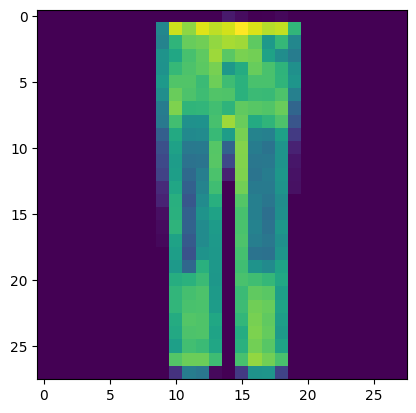

In [11]:
print(np.argmax(model_1.predict(np.array([test_X[15]]))))
plt.imshow(test_X[15])

In [12]:
model_2 = Sequential(
    [ Input((28,28, 1)),
      Conv2D(64, (5, 5), activation='relu', name='layer1'),
      MaxPooling2D(pool_size=(2, 2), name='layer2'),
      Conv2D(128, (5, 5), activation="relu", name='layer3'),
      MaxPooling2D(pool_size=(2, 2), name='layer4'),
      Flatten(),
      Dense(128, activation="relu", name="layer5"),
      Dense(10, activation="softmax")
    ]
)

In [13]:
model_2.compile(optimizer='adagrad',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [14]:
history_2 = model_2.fit(x=train_X, y=train_y, epochs=15, validation_split=0.2)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.5775 - loss: 1.3254 - val_accuracy: 0.7241 - val_loss: 0.7860
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7336 - loss: 0.7357 - val_accuracy: 0.7609 - val_loss: 0.6661
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7652 - loss: 0.6523 - val_accuracy: 0.7694 - val_loss: 0.6249
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7789 - loss: 0.6088 - val_accuracy: 0.7822 - val_loss: 0.5895
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7907 - loss: 0.5779 - val_accuracy: 0.7938 - val_loss: 0.5656
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8006 - loss: 0.5544 - val_accuracy: 0.8029 - val_loss: 0.5410
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8071 - loss: 0.5353 - val_accuracy: 0.8062 - val_loss: 0.5261
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8134 - loss: 0.5190 - 

In [15]:
model_2.evaluate(x=test_X,y=test_y)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8347 - loss: 0.4780


[0.4780253469944, 0.8346999883651733]

In [16]:
model_3 = Sequential(
    [ Input((28,28, 1)),
      Conv2D(64, (5, 5), activation='relu', name='layer1'),
      MaxPooling2D(pool_size=(2, 2), name='layer2'),
      Conv2D(128, (5, 5), activation="relu", name='layer3'),
      MaxPooling2D(pool_size=(2, 2), name='layer4'),
      Flatten(),
      Dense(128, activation="relu", name="layer5"),
      Dense(10, activation="softmax")
    ]
)

In [18]:
model_3.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [19]:
history_3 = model_3.fit(x=train_X, y=train_y, epochs=15, validation_split=0.2)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6819 - loss: 0.8851 - val_accuracy: 0.7853 - val_loss: 0.5905
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8001 - loss: 0.5407 - val_accuracy: 0.8107 - val_loss: 0.5222
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8327 - loss: 0.4636 - val_accuracy: 0.8322 - val_loss: 0.4631
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8497 - loss: 0.4173 - val_accuracy: 0.8553 - val_loss: 0.4090
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8605 - loss: 0.3867 - val_accuracy: 0.8636 - val_loss: 0.3830
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8697 - loss: 0.3629 - val_accuracy: 0.8677 - val_loss: 0.3718
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8758 - loss: 0.3446 - val_accuracy: 0.8769 - val_loss: 0.3464
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8804 - loss: 0.3286 - 

In [20]:
model_3.evaluate(x=test_X,y=test_y)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8870 - loss: 0.3187


[0.318748414516449, 0.8870000243186951]

In [21]:
model_4 = Sequential(
    [ Input((28,28, 1)),
      Conv2D(64, (5, 5), activation='relu', name='layer1'),
      MaxPooling2D(pool_size=(2, 2), name='layer2'),
      Conv2D(128, (5, 5), activation="relu", name='layer3'),
      MaxPooling2D(pool_size=(2, 2), name='layer4'),
      Flatten(),
      Dense(128, activation="relu", name="layer5"),
      Dense(10, activation="softmax")
    ]
)

In [32]:
model_4.compile(optimizer=SGD(learning_rate=0.01, momentum=0.9, nesterov=True),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [33]:
history_4 = model_4.fit(x=train_X, y=train_y, epochs=15, validation_split=0.2)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8799 - loss: 0.3301 - val_accuracy: 0.8857 - val_loss: 0.3182
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8992 - loss: 0.2792 - val_accuracy: 0.8923 - val_loss: 0.2927
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9087 - loss: 0.2476 - val_accuracy: 0.9072 - val_loss: 0.2651
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9177 - loss: 0.2240 - val_accuracy: 0.9032 - val_loss: 0.2679
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9262 - loss: 0.2009 - val_accuracy: 0.9047 - val_loss: 0.2639
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9318 - loss: 0.1835 - val_accuracy: 0.9061 - val_loss: 0.2693
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9379 - loss: 0.1663 - val_accuracy: 0.9022 - val_loss: 0.2776
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9439 - loss: 0.1525 - 

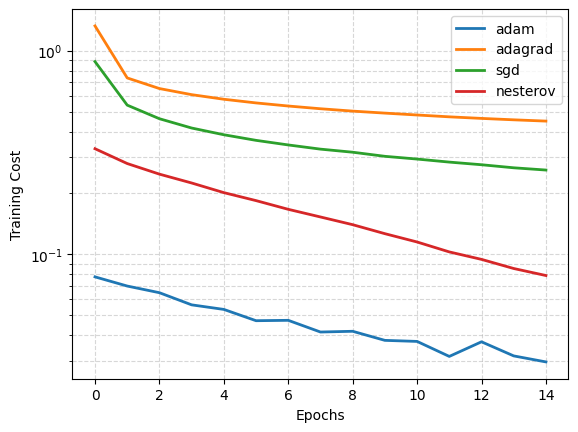

In [34]:
plt.plot(history_1.history['loss'], label='adam', linewidth=2)
plt.plot(history_2.history['loss'], label='adagrad', linewidth=2)
plt.plot(history_3.history['loss'], label='sgd', linewidth=2)
plt.plot(history_4.history['loss'], label='nesterov', linewidth=2)
plt.yscale('log')
plt.xlabel('Epochs')
plt.ylabel('Training Cost')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()